[![../img/pythonista.png](../img/pythonista.png)](https://www.pythonista.io)

# Población, muestra y distribución muestral.

**py401 · EDA Práctico** · Pythonista® · Instructor: José Luis Chiquete · Módulo III: *Inferencia estadística*

> 🔑 **Versión con soluciones.** Solo para el instructor o para revisión posterior.

En este *notebook* se estudiará cómo varía un estadístico de muestra en muestra: la ley de los grandes números, el teorema central del límite y el efecto del tamaño de muestra y del diseño de muestreo.

## 🧭 Cómo usar este *notebook*.

* Ejecuta las celdas **en orden** (`Shift + Enter`).
* 🟢 **Ejercicio básico:** lo que todos deben dominar.
* 🔴 **Reto (opcional):** para quien termina antes o quiere profundizar. Si no da tiempo en clase, se puede resolver como práctica.
* Las celdas `# TU CÓDIGO AQUÍ` y *✍️ Tu respuesta* son para ti.

## 📚 Referencias.

* La generación de números aleatorios con `np.random.default_rng` se explica en [py311 · 04 Arreglos con contenido aleatorio](https://github.com/PythonistaMX/py311/blob/main/04_arreglos_con_contenido_aleatorio.ipynb) y los resúmenes con *NumPy* en [py311 · 07 Gestión y análisis de datos de *NumPy*](https://github.com/PythonistaMX/py311/blob/main/07_gestion_y_analisis_de_datos_de_numpy.ipynb).
* py311 no cubre inferencia, así que la referencia de la API es la documentación oficial: [*SciPy* · `scipy.stats`](https://docs.scipy.org/doc/scipy/reference/stats.html), [*SciPy* · `bootstrap`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.bootstrap.html) y [*statsmodels* · `proportion_confint`](https://www.statsmodels.org/stable/generated/statsmodels.stats.proportion.proportion_confint.html).

> ⚠️ **Nota:** py311 se escribió para *pandas* 2 y este curso usa *pandas* 3; si algo se ve distinto, se sigue lo que muestra este *notebook*.

### Preparación del entorno.

* La siguiente celda importará las bibliotecas, incluidos `stats` de *SciPy* y las funciones de *statsmodels* que se usarán, y definirá `DATA` y la semilla `rng`.

In [1]:
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

DATA = next(os.path.join(p, "data") for p in (os.curdir, os.pardir)
            if os.path.isfile(os.path.join(p, "data", "penguins.csv")))
pd.set_option("display.max_columns", 20)
sns.set_theme(style="whitegrid")
rng = np.random.default_rng(401)
from scipy import stats
from statsmodels.stats.proportion import proportion_confint
from statsmodels.stats.weightstats import DescrStatsW

**¿Por qué este paso?** Se parte del archivo limpio de `09_auditoria_de_calidad.ipynb` para no repetir la limpieza; si no existe (por ejemplo, en un *Codespace* nuevo), se regenera con los mismos pasos mínimos. `titanic` se usará para proporciones y para un ejemplo de datos muy asimétricos.

* La siguiente celda leerá `penguins_limpio.csv` (o lo regenerará desde `penguins.csv` si no existe) y `titanic.csv`.

In [2]:
ruta_limpio = os.path.join(DATA, "penguins_limpio.csv")
medidas = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
if not os.path.isfile(ruta_limpio):
    (
        pd.read_csv(os.path.join(DATA, "penguins.csv"))
        .assign(sex=lambda d: d["sex"].str.title())
        .dropna(subset=medidas, how="all")
        .to_csv(ruta_limpio, index=False)
    )
pinguinos = pd.read_csv(ruta_limpio)
titanic = pd.read_csv(os.path.join(DATA, "titanic.csv"))
pinguinos.shape, titanic.shape

((342, 7), (891, 15))

---
## 1. Repaso: errores frecuentes en un EDA descriptivo (10 min).

Antes de pasar a la inferencia, conviene repasar los puntos que más se descuidan en cualquier EDA descriptivo (por ejemplo, el de `tips` de la práctica integradora del `15`):

| Aspecto | Error frecuente | Lo que se espera |
|---|---|---|
| Calidad | Revisar faltantes pero no duplicados ni `dtypes` | Lista de verificación completa de `09_auditoria_de_calidad` |
| Descripción | Reportar solo media y desviación estándar de `tip_pct`, que es asimétrica y tiene atípicos | Mediana e IQR, o ambas con la justificación |
| Agregación | Comparar medias por grupo sin el número de cuentas de cada grupo | Tabla con *n* por celda (en `tips`, las comidas son casi todas en jueves) |
| Gráficas | Barras de medias sin dispersión, ejes sin unidades | Diagramas de caja o puntos con dispersión; títulos con el hallazgo |
| Conclusiones | "Los fumadores dejan más propina porque…" | Lenguaje descriptivo: "en estos datos, la mediana fue…" |

Hoy se agrega la pieza que le falta a un EDA descriptivo: **¿qué tan seguros estamos de esos números?**

---
## 2. Población, muestra y distribución muestral (30 min).

En `05_muestreo_y_sesgos_de_recoleccion.ipynb` se distinguieron los **parámetros** (los valores verdaderos de la población, como su masa media y su desviación estándar) y los **estadísticos** (los mismos cálculos hechos con la muestra). Un estadístico **cambia con la suerte**: si se repitiera el muestreo, saldría otro valor (por eso se dice que es una *variable aleatoria*). Toda la inferencia de los *notebooks* `17` a `22` descansa en una pregunta: **¿cuánto cambiaría el estadístico de una muestra a otra?**

* **Población:** todos los individuos de interés. Su media (el promedio de todos) casi nunca se conoce.
* **Muestra:** los individuos que sí se midieron; cuántos son se anota como *n*. Su media se usa para **estimar** la de la población.
* **Distribución muestral:** cómo se reparten las medias que se obtendrían con todas las muestras posibles del mismo tamaño. Cuánto varían esas medias se llama **error estándar** (EE).

El error estándar de la media sigue una regla sencilla, la única fórmula que conviene recordar de este *notebook*:

**error estándar de la media = desviación estándar de los individuos ÷ raíz cuadrada de *n***

**Ejemplo:** las masas de los pingüinos varían unos 800 g de un individuo a otro. Si se promedian 25 pingüinos, como la raíz cuadrada de 25 es 5, el promedio varía unos 800 ÷ 5 = 160 g de una muestra a otra.

No hay que confundir la **desviación estándar** (cuánto varían los **individuos**) con el **error estándar** (cuánto varía la **estimación**). **Ejemplo cotidiano:** las estaturas de los alumnos de una escuela varían mucho, pero el promedio de estatura de un salón de 40 cambia poco de un salón a otro.

Para **ver** la distribución muestral se necesita conocer la población. Por eso, solo en esta sección, se tratarán los 342 pingüinos con masa registrada como si fueran la población completa y se sacarán muchas muestras de ella. Se muestrea **con reemplazo** (un pingüino puede salir más de una vez), como si la población fuera muy grande; así la regla anterior se cumple exactamente.

* La siguiente celda definirá la población de juguete y su media y desviación estándar.

In [3]:
poblacion = pinguinos["body_mass_g"].dropna().to_numpy()
mu, sigma = poblacion.mean(), poblacion.std()
round(float(mu), 1), round(float(sigma), 1)

(4201.8, 800.8)

**Interpretación:** en esta población de juguete, la media es ≈ 4,201.8 g y la desviación estándar ≈ 800.8 g (en el código se llaman `mu` y `sigma`, como las letras griegas que usan los libros). Se usa `std()` de *NumPy* (con `ddof=0`) porque aquí se trata de la población completa, no de una muestra.

### 2.1 Ley de los grandes números.

La **ley de los grandes números** dice que, al aumentar el tamaño de la muestra, la media de la muestra se acerca cada vez más a la media de la población.

**Ejemplo cotidiano:** si se lanza una moneda 10 veces, pueden salir 7 águilas (70%); con 10,000 lanzamientos, el porcentaje de águilas queda muy cerca de 50%.

Es la justificación de que "más datos dan mejores estimaciones". Para verla, se sacará una sola secuencia larga de pingüinos y se calculará la **media acumulada** después de cada nuevo dato (el promedio del primero, luego de los dos primeros, luego de los tres primeros…). Se usa un generador local con semilla 401 para que los resultados no dependan de las celdas anteriores.

* La siguiente celda sacará 5,000 pingüinos al azar, calculará la media acumulada y la dibujará frente a la media de la población (línea punteada; μ en el título).

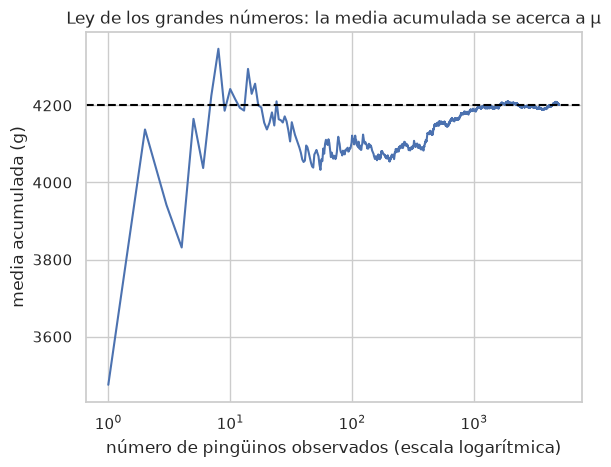

{1: 3475.0, 10: 4242.5, 100: 4121.5, 1000: 4186.2, 5000: 4201.1}

In [4]:
generador_lgn = np.random.default_rng(401)
secuencia = generador_lgn.choice(poblacion, size=5000)
media_acumulada = np.cumsum(secuencia) / np.arange(1, len(secuencia) + 1)
ax = sns.lineplot(x=np.arange(1, len(secuencia) + 1), y=media_acumulada)
ax.axhline(mu, color="black", linestyle="--")
ax.set(xscale="log", xlabel="número de pingüinos observados (escala logarítmica)", ylabel="media acumulada (g)",
       title="Ley de los grandes números: la media acumulada se acerca a μ")
plt.show()
{n: round(float(media_acumulada[n - 1]), 1) for n in [1, 10, 100, 1000, 5000]}

**Interpretación:** con un pingüino la "media" es 3,475 g, a más de 700 g de la media de la población; con 100 está a unos 80 g, y con 5,000 a menos de 1 g. Las oscilaciones iniciales son grandes y se amortiguan rápido. **Error común que se evita:** la ley de los grandes números **no** dice que la muestra "compense" una racha (la falacia del jugador); dice que el peso de cada racha se diluye al crecer la muestra. Tampoco dice **qué tan rápido** se acerca: eso lo responde el error estándar (sección 2.3).

### 2.2 Teorema central del límite.

El **teorema central del límite** (TCL) describe la **forma** de la distribución muestral: si las observaciones son independientes (una no influye en otra) y la muestra es suficientemente grande, las medias de muchas muestras forman una **campana** (distribución normal) centrada en la media de la población, con un ancho igual al error estándar. Y esto ocurre **sin importar la forma de la población**.

**Ejemplo cotidiano:** un solo dado da 1, 2, 3, 4, 5 o 6 con la misma probabilidad (no tiene forma de campana). Pero si se lanzan 10 dados y se promedian, y eso se repite muchas veces, los promedios se juntan alrededor de 3.5 en forma de campana: es muy raro que el promedio de 10 dados salga 1 o 6.

Es la razón por la que las fórmulas de intervalos y pruebas de los *notebooks* `17` a `22` usan la distribución normal o la *t*. Ojo: la campana es la de las **medias** de muestras repetidas muchas veces, no la de los datos. Primero se verá con la masa de los pingüinos, una población que **no** tiene forma de campana (un pico grande y un hombro hacia las masas altas).

* La siguiente celda sacará 2,000 muestras de tamaño 25 y guardará la media de cada una.

In [5]:
medias_25 = rng.choice(poblacion, size=(2000, 25)).mean(axis=1)
round(float(medias_25.mean()), 1), round(float(medias_25.std()), 1)

(4207.2, 159.0)

* La siguiente celda comparará la distribución de la población con la distribución muestral de la media.

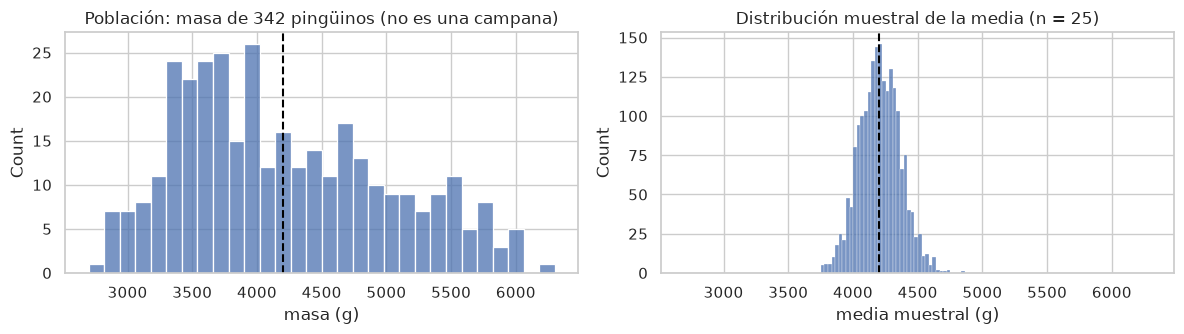

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5), sharex=True)
sns.histplot(poblacion, bins=30, ax=axes[0]).set(title="Población: masa de 342 pingüinos (no es una campana)", xlabel="masa (g)")
sns.histplot(medias_25, bins=40, ax=axes[1]).set(title="Distribución muestral de la media (n = 25)", xlabel="media muestral (g)")
for ax in axes:
    ax.axvline(mu, color="black", linestyle="--")
plt.tight_layout()
plt.show()

**Interpretación:** aunque la población no tiene forma de campana, las medias de muestras de 25 se distribuyen con forma de campana alrededor de la media de la población: es el TCL en acción. Su centro coincide con la media de la población (en promedio, la media de la muestra le atina: es **insesgada**) y su dispersión, unos 160 g, es el error estándar: 800.8 ÷ 5 (la raíz cuadrada de 25) ≈ 160 g, cinco veces menor que la dispersión de los individuos.

> 💡 **Ley de los grandes números contra teorema central del límite:** la ley de los grandes números dice **hacia dónde** va la media de una muestra que sigue creciendo (hacia la media de la población). El teorema central del límite dice **cómo se reparten**, alrededor de esa media, las medias de muestras del mismo tamaño (suficientemente grandes), vistas en muchas repeticiones (en una campana cuyo ancho es el error estándar). La primera habla de una sola muestra que crece; el segundo, de muchas muestras de tamaño fijo.

**¿Qué tan grande debe ser *n*?** Depende de la población. La regla "con 30 datos o más basta" funciona con poblaciones parecidas a la normal, pero falla con poblaciones muy asimétricas. Se probará con la **tarifa del Titanic** (asimetría ≈ 4.8: muchas tarifas bajas y unas pocas altísimas), midiendo la asimetría de la distribución de las medias. Una distribución normal tiene asimetría 0.

* La siguiente celda dibujará la distribución de la media de la tarifa para muestras de 1, 5, 30 y 100 pasajeros, y calculará su asimetría y su error estándar simulado y con la regla (columna `σ / √n`: desviación estándar ÷ raíz cuadrada de *n*).

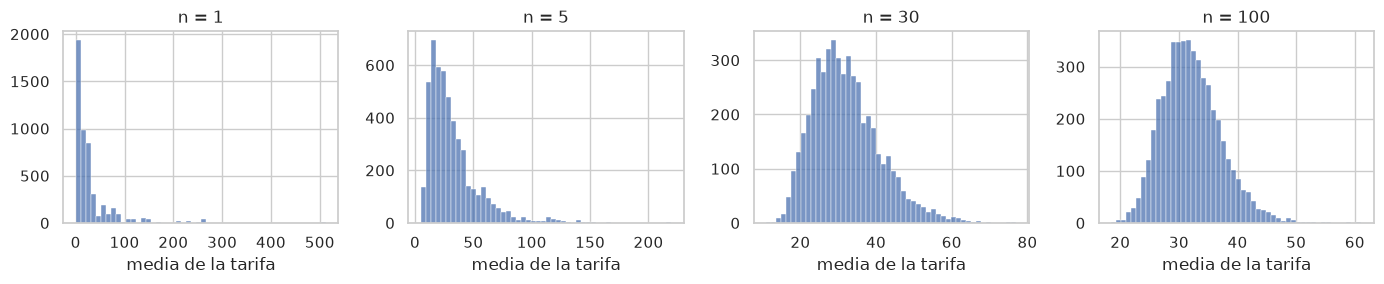

,asimetría,EE simulado,σ / √n
1,4.43,48.55,49.67
5,2.25,22.50,22.21
30,0.80,8.93,9.07
100,0.61,5.03,4.97


In [7]:
generador_tcl = np.random.default_rng(401)
tarifas = titanic["fare"].to_numpy()
fig, axes = plt.subplots(1, 4, figsize=(14, 3))
filas_tcl = {}
for ax, n_tcl in zip(axes, [1, 5, 30, 100]):
    medias_tarifa = generador_tcl.choice(tarifas, size=(5000, n_tcl)).mean(axis=1)
    sns.histplot(medias_tarifa, bins=50, ax=ax).set(title=f"n = {n_tcl}", xlabel="media de la tarifa", ylabel="")
    filas_tcl[n_tcl] = {"asimetría": stats.skew(medias_tarifa), "EE simulado": medias_tarifa.std(),
                        "σ / √n": tarifas.std() / np.sqrt(n_tcl)}
plt.tight_layout()
plt.show()
pd.DataFrame(filas_tcl).T.round(2)

**Interpretación:** con muestras de 1 pasajero, la "distribución de la media" es la población misma (asimetría ≈ 4.4 en la simulación; el valor exacto en los datos es 4.8, y la diferencia es ruido de simulación). En la simulación la asimetría baja a ≈ 2.3 con 5 pasajeros, a ≈ 0.8 con 30 y a ≈ 0.6 con 100. Los valores exactos, que salen de dividir 4.8 entre la raíz cuadrada de *n*, son 4.8, 2.1, 0.9 y 0.5 (la simulación con 5,000 repeticiones solo los aproxima). En cualquier caso, la distribución se acerca a la normal, pero **lentamente**. En cambio, el error estándar simulado coincide con la regla (columna `σ / √n`) en todos los casos, porque esa regla no depende de la forma de la población.

**Decisión que permite tomar:** con datos tan asimétricos, 30 datos no bastan para confiar en la aproximación normal; esto explica la mala cobertura que se verá en la sección 1.2 de `17_error_estandar_e_intervalos_de_confianza.ipynb`. Conviene revisar la forma de los datos (`11_forma_de_la_distribucion`) antes de usar una fórmula basada en el TCL. **Error común que se evita:** creer que el TCL vuelve normales **los datos**; solo vuelve aproximadamente normal **la media**.

### 2.3 Efecto del tamaño de muestra: el error estándar baja con √*n*.

Como el error estándar es la desviación estándar dividida entre la **raíz cuadrada** de *n*, cuadruplicar la muestra reduce el error estándar **a la mitad** (la raíz cuadrada de 4 es 2), no a la cuarta parte: la precisión cuesta cada vez más datos. Para pasar de un EE de 80 g a uno de 40 g hacen falta 300 pingüinos más (de 100 a 400); para bajar a 20 g, otros 1,200 (de 400 a 1,600).

| Tamaño de muestra *n* | Error estándar de la masa (g) |
|---:|---:|
| 25 | 160 |
| 100 | 80 |
| 400 | 40 |
| 1,600 | 20 |
| 10,000 | 8 |

(Cada fila es 800.8 ÷ raíz cuadrada de *n*, redondeado.)

* La siguiente celda comparará el error estándar simulado con la regla (columna `σ / √n`: desviación estándar ÷ raíz cuadrada de *n*) para tres tamaños de muestra.

In [8]:
pd.DataFrame({
    n: {"EE simulado": rng.choice(poblacion, size=(2000, n)).mean(axis=1).std(),
        "σ / √n": sigma / np.sqrt(n)}
    for n in [25, 100, 400]
}).T.round(1)

,EE simulado,σ / √n
25,164.0,160.2
100,78.7,80.1
400,40.0,40.0


**Interpretación:** la simulación confirma la fórmula: ≈ 160, 80 y 40 g para 25, 100 y 400 pingüinos. Cada vez que *n* se multiplica por 4, el EE se divide entre 2. **Decisión que permite tomar:** dimensionar una muestra antes de recolectar datos. Si se quiere un EE de 50 g, la raíz cuadrada de *n* debe ser 800.8 ÷ 50 ≈ 16; como 16 × 16 = 256, hacen falta unos 257 pingüinos.

### 2.4 📖 Lectura opcional en clase: efecto del diseño (estratificado contra aleatorio simple).

En `05_muestreo_y_sesgos_de_recoleccion` se vio que estratificar por especie daba estimaciones más estables. Ahora se cuantificará. En un muestreo **estratificado**, la población se divide en grupos (estratos; aquí, las especies), se sortea dentro de cada uno y la media final combina la media de cada especie, dándole a cada una el **peso** de su proporción en la población.

Con asignación **proporcional** (cada especie entra en la muestra en la misma proporción que en la población), el error estándar de esa media solo depende de la variabilidad **dentro** de los estratos. La variabilidad **entre** estratos (que los Gentoo pesen en promedio unos 1,375 g más que los Adelie) desaparece del error. Por eso estratificar rinde mucho cuando los estratos difieren entre sí.

**Ejemplo cotidiano:** para estimar la estatura promedio de una escuela con primaria y secundaria, sortear por separado en cada nivel evita que, por mala suerte, la muestra quede llena de niños de primaria.

* La siguiente celda calculará los pesos y las desviaciones estándar de cada especie en la población.

In [9]:
poblacion_especies = pinguinos.dropna(subset=["body_mass_g"])
pesos_estrato = poblacion_especies["species"].value_counts(normalize=True).sort_index()
sigma_estrato = poblacion_especies.groupby("species")["body_mass_g"].std(ddof=0)
masas_estrato = {especie: datos["body_mass_g"].to_numpy() for especie, datos in poblacion_especies.groupby("species")}
pd.DataFrame({"peso W_h": pesos_estrato, "σ_h (g)": sigma_estrato}).round(3)

,peso W_h,σ_h (g)
species,,
Adelie,0.442,457.045
Chinstrap,0.199,381.499
Gentoo,0.360,502.063


**Interpretación:** las desviaciones estándar **dentro** de cada especie (380 a 500 g) son mucho menores que la de la población completa (800.8 g), porque buena parte de la variación total se debe a las diferencias **entre** especies.

* La siguiente celda simulará 5,000 muestras de cada diseño para *n* = 30, 60 y 120 y comparará los errores estándar simulados con sus fórmulas.

In [10]:
generador_diseno = np.random.default_rng(401)
filas_diseno = {}
for n_total in [30, 60, 120]:
    n_estrato = {especie: int(round(n_total * peso)) for especie, peso in pesos_estrato.items()}
    medias_simple = generador_diseno.choice(poblacion, size=(5000, n_total)).mean(axis=1)
    medias_estratificado = sum(
        pesos_estrato[especie] * generador_diseno.choice(masas_estrato[especie], size=(5000, n_h)).mean(axis=1)
        for especie, n_h in n_estrato.items()
    )
    filas_diseno[n_total] = {
        "EE simple (simulado)": medias_simple.std(),
        "EE simple (fórmula)": sigma / np.sqrt(n_total),
        "EE estratificado (simulado)": medias_estratificado.std(),
        "EE estratificado (fórmula)": np.sqrt(sum(pesos_estrato[e] ** 2 * sigma_estrato[e] ** 2 / n_h for e, n_h in n_estrato.items())),
    }
tabla_diseno = pd.DataFrame(filas_diseno).T
tabla_diseno["efecto de diseño"] = (tabla_diseno["EE estratificado (fórmula)"] / tabla_diseno["EE simple (fórmula)"]) ** 2
tabla_diseno.round(2)

,EE simple (simulado),EE simple (fórmula),EE estratificado (simulado),EE estratificado (fórmula),efecto de diseño
30,148.58,146.20,83.46,84.00,0.33
60,102.51,103.38,59.33,59.39,0.33
120,73.83,73.10,41.97,42.03,0.33


**Interpretación:** con el mismo número de pingüinos, el diseño estratificado tiene un error estándar de **poco más de la mitad** que el aleatorio simple (≈ 59 contra 103 g con *n* = 60), y la simulación coincide con la fórmula. El cociente de varianzas, llamado **efecto de diseño**, es ≈ 0.33: un estratificado con 60 pingüinos es tan preciso como un aleatorio simple con unos 180. En `05_muestreo_y_sesgos_de_recoleccion` el EE estratificado salió aún menor (≈ 52 g) porque allí se muestreó **sin reemplazo** de una población de solo 342: medir una fracción grande de la población reduce el error adicionalmente (corrección por población finita).

**Decisión que permite tomar:** si se conoce una variable que explica mucho de lo que se mide (especie, región, nivel socioeconómico), conviene estratificar por ella. **Error común que se evita:** analizar una muestra estratificada con **asignación no proporcional** como si fuera aleatoria simple, sin ponderar por el peso de cada estrato (la proporción de la población que representa); eso sesga la media.

📖 **Para profundizar (opcional).** *La sección 2 en símbolos.* En libros y en las respuestas de una IA, la media de la población se escribe $\mu$, su desviación estándar $\sigma$, la media de la muestra $\bar{x}$ y su desviación estándar $s$.

* Error estándar de la media: $$EE(\bar{x}) = \frac{\sigma}{\sqrt{n}}$$
* Ley de los grandes números: $\bar{x}_n \xrightarrow[n \to \infty]{} \mu$.
* Teorema central del límite (observaciones independientes y con varianza finita): $\bar{x} \;\approx\; \mathcal{N}\!\left(\mu,\; \frac{\sigma^2}{n}\right)$ para $n$ suficientemente grande.
* Muestreo estratificado (sección 2.4): con $H$ estratos de pesos $W_h = N_h / N$ y desviaciones estándar $\sigma_h$, la media estratificada es $\bar{x}_{st} = \sum_h W_h \bar{x}_h$ y su error estándar es $$EE(\bar{x}_{st}) = \sqrt{\sum_{h=1}^{H} \frac{W_h^2\, \sigma_h^2}{n_h}}$$ Con asignación proporcional ($n_h = n W_h$) se simplifica a $\sqrt{\sum_h W_h \sigma_h^2 / n}$. La asignación de Neyman (reto 1) reparte la muestra en proporción a $W_h \sigma_h$ en lugar de $W_h$. En la tabla de la sección 2.4, las columnas `peso W_h` y `σ_h (g)` son esos $W_h$ y $\sigma_h$.

**💡 Ideas clave de la sección 2:**
* Un estadístico varía de muestra en muestra; su distribución es la **distribución muestral** y su desviación estándar, el **error estándar**.
* Ley de los grandes números: la media de la muestra se acerca a la de la población al crecer la muestra. TCL: las medias de muestras suficientemente grandes, vistas en muchas repeticiones, forman una campana, y la forman más rápido cuanto menos asimétrica sea la población.
* **error estándar de la media = desviación estándar de los individuos ÷ raíz cuadrada de *n***: cuadruplicar *n* reduce el EE a la mitad.
* El diseño también importa: estratificar por una variable que separa a la población reduce el EE sin aumentar *n*.

### 🟢 Ejercicio 1 · ¿Media o mediana?

**🎯 Objetivo:** comparar la **eficiencia** de dos estimadores del centro, es decir, cuánto varía cada uno de muestra a muestra. **Qué se espera aprender:** que el error estándar no es solo de la media: cada estimador tiene su distribución muestral, y elegir uno es elegir también su precisión.

Con `poblacion`, saca 2,000 muestras de tamaño 25 (usa `generador = np.random.default_rng(401)`) y calcula para cada una la **media** y la **mediana**. ¿Cuál de los dos estimadores varía más de muestra a muestra? Compara sus desviaciones estándar y dibuja ambas distribuciones.

* La siguiente celda muestra una solución posible.

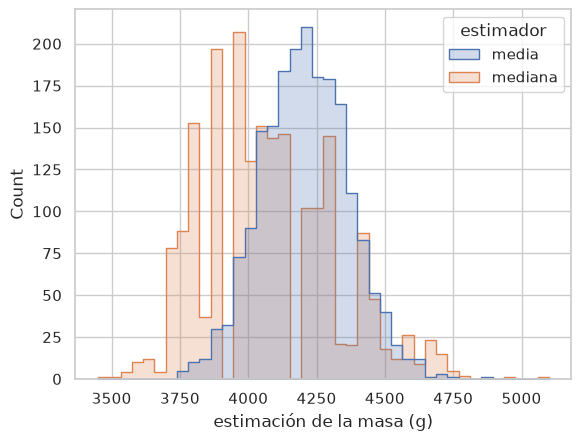

media      159.1
mediana    241.5
dtype: float64

In [11]:
generador = np.random.default_rng(401)
muestras = generador.choice(poblacion, size=(2000, 25))
estimadores = pd.DataFrame({"media": muestras.mean(axis=1), "mediana": np.median(muestras, axis=1)})
sns.histplot(estimadores.melt(var_name="estimador", value_name="valor"), x="valor", hue="estimador",
             element="step", bins=40)
plt.xlabel("estimación de la masa (g)")
plt.show()
estimadores.std().round(1)

**✅ Respuesta sugerida:**

La mediana varía más (su desviación estándar es mayor que la de la media, que ronda 160 g). En esta población bimodal la mediana "salta" entre los dos picos según cuántos Gentoo caigan en la muestra. La media es más eficiente cuando no hay atípicos; la mediana compensa ese costo cuando sí los hay.

### 🔴 Reto 1 · Asignación de Neyman.

**🎯 Objetivo:** explorar cómo repartir una muestra entre estratos. **Qué se espera aprender:** cuándo vale la pena una asignación más sofisticada que la proporcional.

La **asignación de Neyman** reparte la muestra tomando en cuenta no solo el tamaño de cada estrato, sino también **cuánto varía**: se muestrean más individuos donde hay más variabilidad (las fórmulas están en el bloque 📖 al final de la sección 2). Con *n* = 60, calcula cuántos pingüinos de cada especie asigna Neyman y el EE estratificado con la fórmula, y compáralo con el de la asignación proporcional (sección 2.4). ¿Cuánto se gana?

* La siguiente celda muestra una solución posible.

In [12]:
producto = pesos_estrato * sigma_estrato
n_neyman = (60 * producto / producto.sum()).round().astype(int)
ee_neyman = np.sqrt(sum(pesos_estrato[e] ** 2 * sigma_estrato[e] ** 2 / n_h for e, n_h in n_neyman.items()))
n_neyman.to_dict(), round(float(ee_neyman), 1), round(float(tabla_diseno.loc[60, "EE estratificado (fórmula)"]), 1)

({'Adelie': 26, 'Chinstrap': 10, 'Gentoo': 24}, 59.2, 59.4)

**✅ Respuesta sugerida:**

Neyman asigna 26 Adelie, 10 Chinstrap y 24 Gentoo (la proporcional, 26/12/22) y el EE pasa de 59.4 a 59.2 g: prácticamente nada. Neyman solo gana mucho cuando las desviaciones estándar de los estratos son muy distintas entre sí; aquí son parecidas (380 a 500 g). La ganancia grande vino de **estratificar**, no de cómo se reparte la muestra.

---
## ✅ Cierre.

**Práctica (en Classroom):** terminar los ejercicios 🟢 pendientes de este *notebook* y, si es posible, un reto 🔴.

**Siguiente *notebook*:** `17_error_estandar_e_intervalos_de_confianza.ipynb`.

<p style="text-align: center"><a rel="license" href="http://creativecommons.org/licenses/by/4.0/"><img alt="Licencia Creative Commons" style="border-width:0" src="https://i.creativecommons.org/l/by/4.0/80x15.png" /></a><br />Esta obra está bajo una <a rel="license" href="http://creativecommons.org/licenses/by/4.0/">Licencia Creative Commons Atribución 4.0 Internacional</a>.</p>
<p style="text-align: center">&copy; José Luis Chiquete Valdivieso. 2017-2026.</p>